In [15]:
import Symmetric as symdali
import numpy as np
import emcee
import getdist
from getdist import plots
import matplotlib.pyplot as plt

In [18]:
#the fiducial point around which we expanded likelihood
pf = np.array([
   -0.883787, 6.18412, 0.471846, 190.258, 0.935815, 0.107562,
   -0.0254365, 2.60021, 35.1128, 61093.87906420612, 5.93578
])

#Change dL -> 1/dL
pf2 = pf.copy()
pf2[8] = 1/pf[8]

tensors = np.loadtxt('taylor.txt')

def DALI_L(p):

    #Change dL -> 1/dL
   i_p = p.copy()
   i_p[8] = 1 / p[8]

   Delta_theta = i_p - pf2

   log_L = np.dot(
      symdali.Taylor_DeltaPs(Delta_theta, 3),
      tensors
   )

   return log_L

In [6]:
a = np.array([
   -np.pi/2, 0., 0., # dec, phi, psi
   140, 0.125, -0.99, -0.99, # Mc, q, s1z, s2z
   0., 1, 61094.012-0.2, 0 # iota, dL, tc, phi_ref
])

b = np.array([
   np.pi/2, 2*np.pi, np.pi, # dec, phi, psi
   240., 1., 0.99, 0.99, # Mc, q, s1z, s2z
   np.pi, 40., 61094.012 + 0.2, 2*np.pi # iota, dL, tc, phi_ref
 ])


In [7]:
#Define transformations to the cube and from it:
cube_length=200

inv_scale = cube_length / (b - a)

scale = (b - a) / cube_length

def from_cube(y):
   return y * scale + a


def to_cube(x):
   return (x - a) * inv_scale


In [8]:
def emcee_logP(y):
   if y.min() < 0 or y.max() > 200:
      return -np.inf

   return DALI_L(from_cube(y))

In [11]:
#Here we set the walkers and initial steps
p0 = np.random.uniform(0, 200, size=(100, 11))
nwalkers, ndim = p0.shape

#RUN EMCEE
import emcee
sampler = emcee.EnsembleSampler(nwalkers, ndim, emcee_logP, a=1)


sampler.run_mcmc(p0, int(5e5), progress=True);

#Calculate the auto correlation time
tau = sampler.get_autocorr_time()

# the emcee recomendation is to discard 2xtau and thin the chain by tau/2
flat_samples = sampler.get_chain(
   discard=int(2*tau.max()),
   thin=int(tau.max()/2),
   flat=True
)

#The samples are in the cube variables y in (0,200)
# Here we transform them back to the original intervals
flat_samples = from_cube(flat_samples)

100%|████████████████████████████████████████████████████████████| 500000/500000 [07:52<00:00, 1058.79it/s]


Removed no burn in


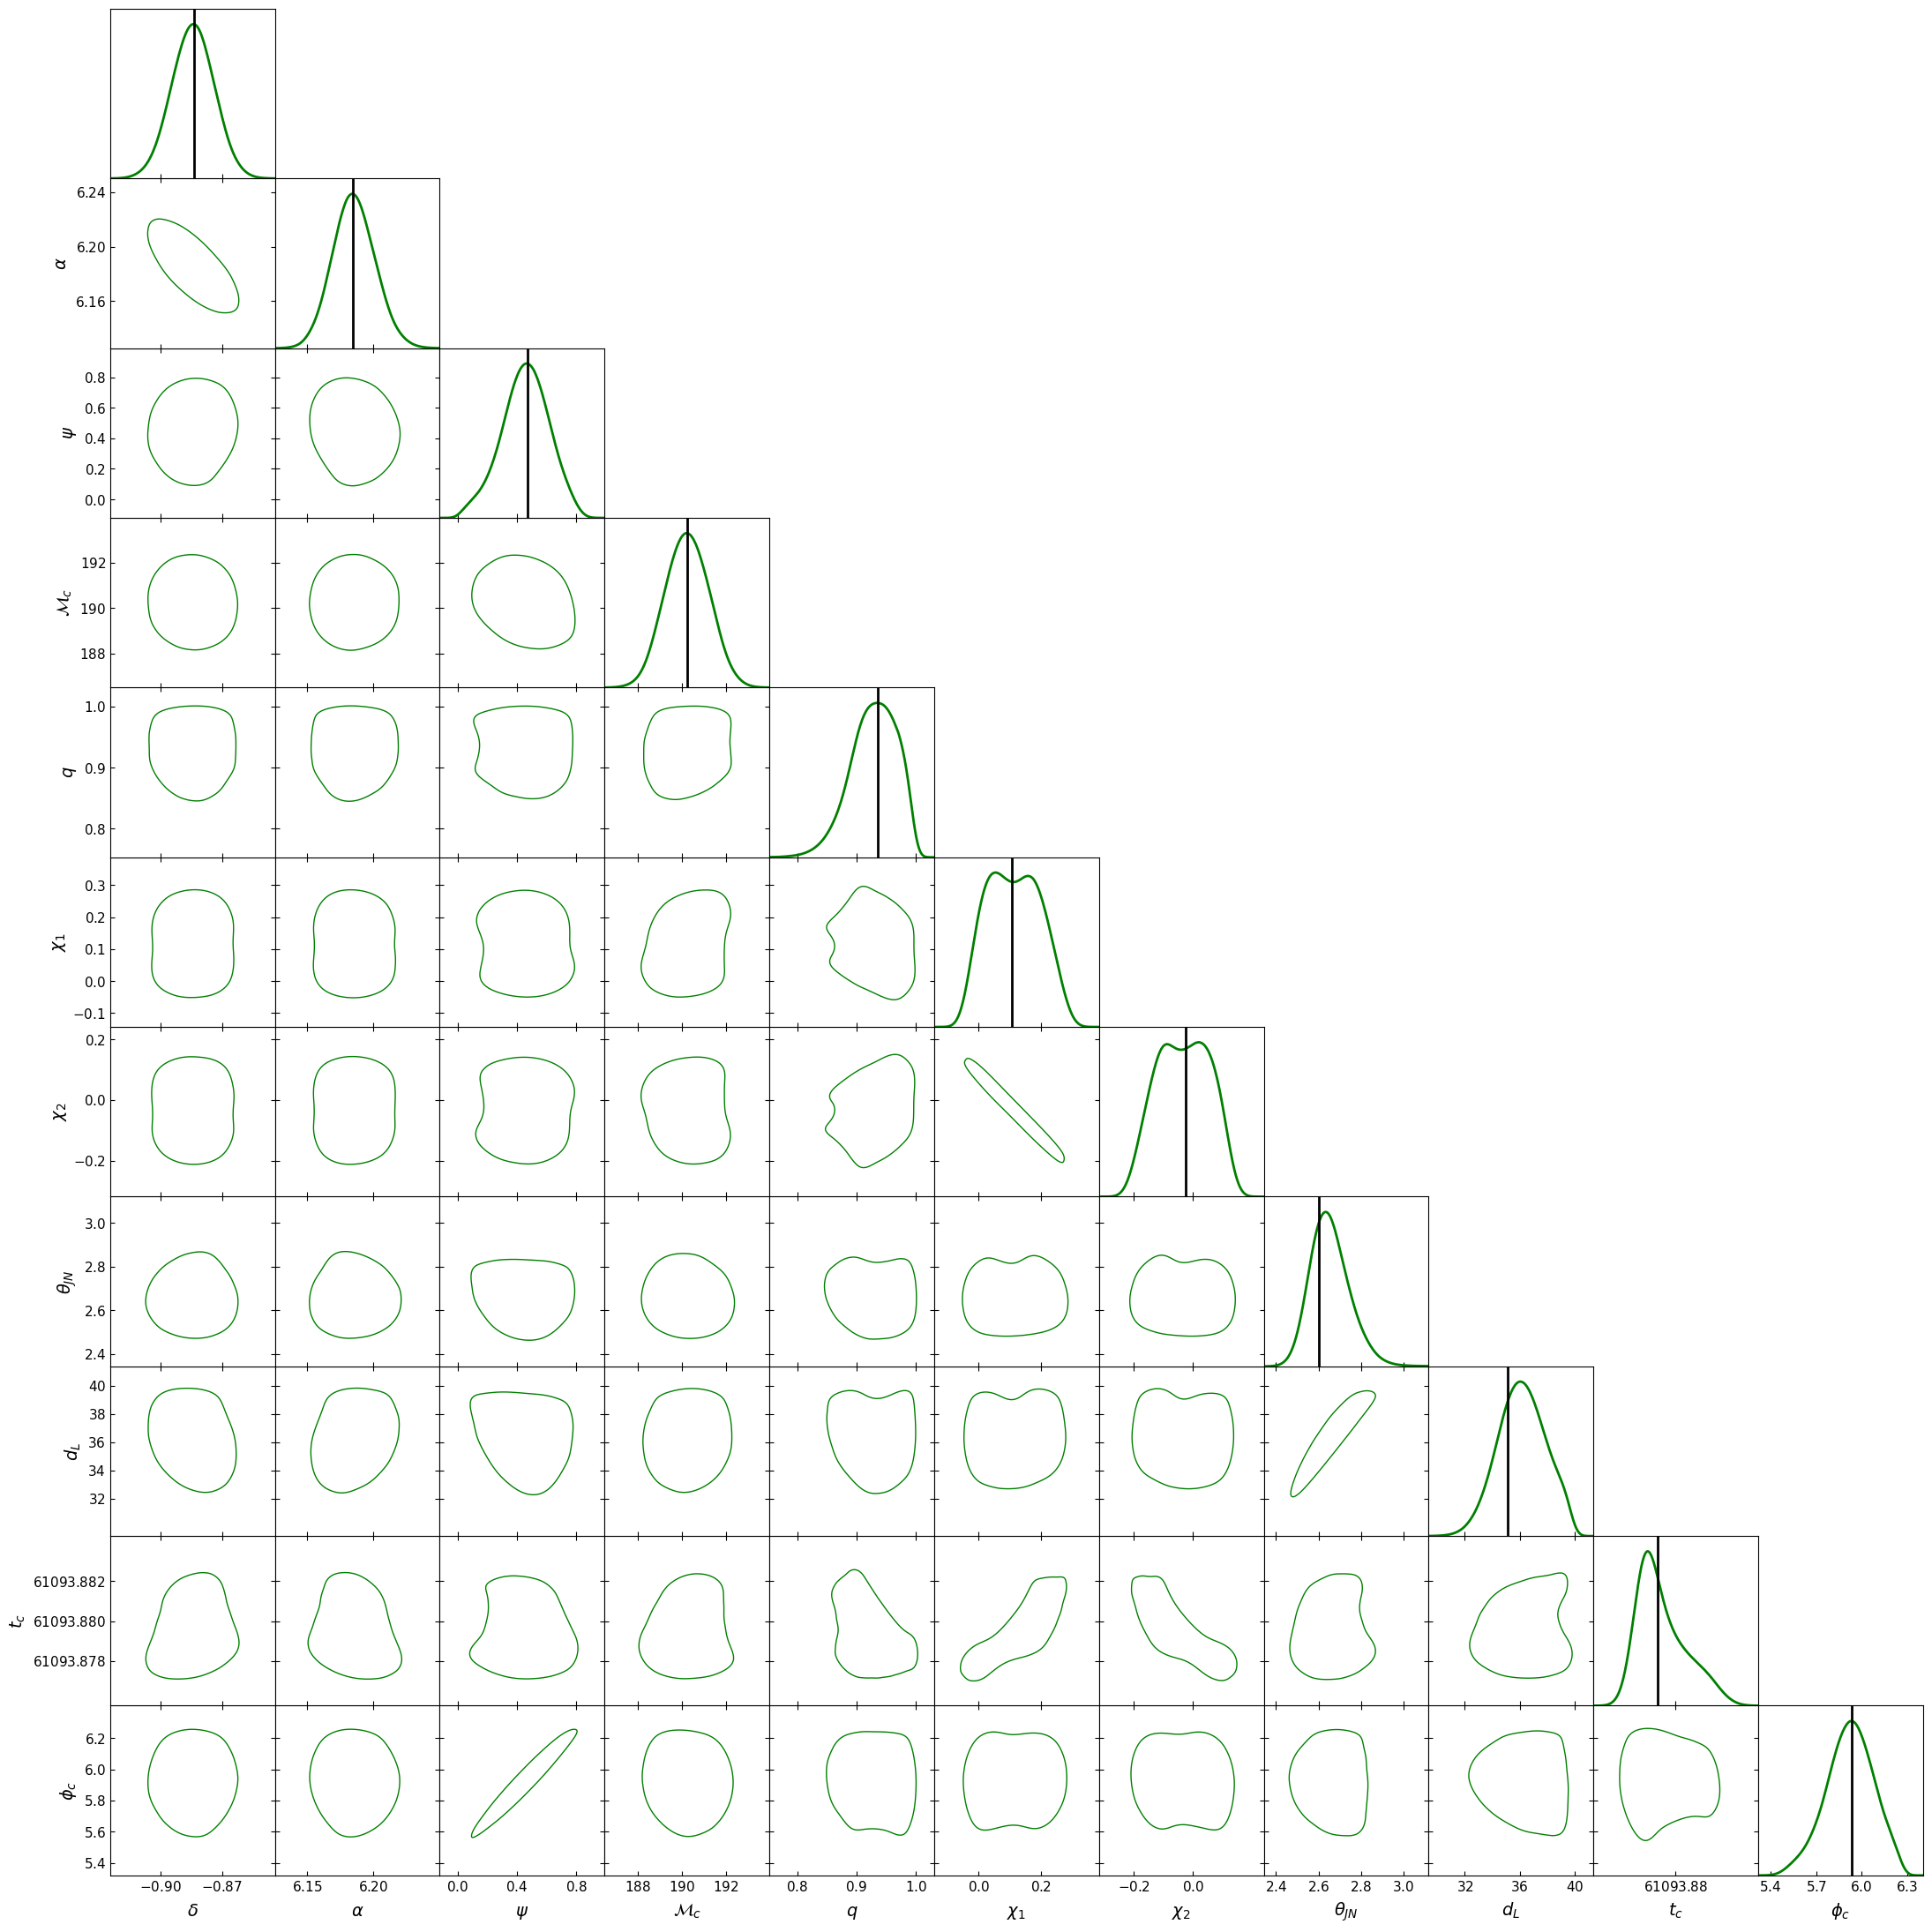

In [19]:
#observe that for the injection value of t_c the right ascension and azimuthal angle
#are equivalent
labels = [
   'dec', 'ra', 'psi',
   'chirp_mass', 'mass_ratio','chi_1', 'chi_2',
   'theta_jn', 'luminosity_distance', 'geocent_time', 'phase'
]

latex_labels = [
   r'\delta', r'\alpha', r'\psi',
   r'\mathcal{M}_c', 'q', r'\chi_1', r'\chi_2',
   r'\theta_{JN}', r'd_L', r't_c', r'\phi_c'
]


samples = getdist.MCSamples(
   samples=flat_samples,
   names = labels,
   labels = latex_labels,
   label='Triplet'
)

samples.smooth_scale_1D = 0.3
samples.contours = [0.9]

g = plots.get_subplot_plotter(scaling=False)
g.settings.figure_legend_frame = False
g.settings.legend_fontsize = 50

g.triangle_plot(
   [samples],
   filled=False,
   contour_colors=['g'],
   line_args = [
      {'lw':2, 'color':'g'}
   ],
   legend_loc='upper right',
   marker_args={'lw': 2,'color':'r', "alpha":1},
)

if g.fig.legends:
    leg = g.fig.legends[0]
    for line in leg.get_lines():
        line.set_linewidth(5)


# add truth only to 1D panels (diagonal)
pf = dict(zip(labels, pf))
truth = pf

for i, p in enumerate(list(pf.keys())):
   ax = g.subplots[i, i]   # diagonal axis
   ax.axvline(truth[p], color='k', lw=2)



fig = g.fig


plt.savefig('example.pdf', dpi=300, bbox_inches='tight')